# Section 4. FDM Pricing and Delta

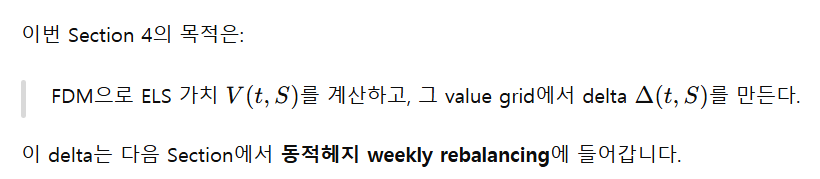

ELS의 시간-가격별 가치 격자(value grid)를 FDM으로 계산하고, 그 value grid에서 delta grid를 만든다.

In [1]:
# ============================================================
# Section 4. FDM Pricing and Delta
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from dataclasses import dataclass

import warnings
warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", 50)
pd.set_option("display.max_rows", 50)
pd.set_option("display.float_format", "{:,.6f}".format)

SEED = 42
np.random.seed(SEED)

In [2]:
# ============================================================
# 4-0. Project Directory Setting
# ============================================================

PROJECT_NAME = "ELS hege 5.19"
CURRENT_DIR = Path.cwd()


def find_project_dir(project_name=PROJECT_NAME):
    """
    Resolve the local project folder from the notebook folder, a subfolder,
    or the parent workspace folder.
    """
    current = Path.cwd().resolve()

    if current.name == project_name:
        return current

    for parent in current.parents:
        if parent.name == project_name:
            return parent

    for base in [current, *current.parents]:
        candidate = base / project_name
        if candidate.exists():
            return candidate.resolve()

    return current / project_name


PROJECT_DIR = find_project_dir()

DATA_DIR = PROJECT_DIR / "data"
OUTPUT_DIR = PROJECT_DIR / "output"
FIGURE_DIR = PROJECT_DIR / "figures"
CODE_DIR = PROJECT_DIR

DATA_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

KOSPI200_PATH = DATA_DIR / "kospi200_close_new.csv"

print("CURRENT_DIR:", CURRENT_DIR)
print("PROJECT_DIR:", PROJECT_DIR)
print("DATA_DIR:", DATA_DIR)
print("OUTPUT_DIR:", OUTPUT_DIR)
print("FIGURE_DIR:", FIGURE_DIR)
print("CODE_DIR:", CODE_DIR)
print("KOSPI200_PATH:", KOSPI200_PATH)
print("Data file exists:", KOSPI200_PATH.exists())


CURRENT_DIR: c:\Users\Yeonsoo\Desktop\project\ELS hege 5.19
PROJECT_DIR: C:\Users\Yeonsoo\Desktop\project\ELS hege 5.19
DATA_DIR: C:\Users\Yeonsoo\Desktop\project\ELS hege 5.19\data
OUTPUT_DIR: C:\Users\Yeonsoo\Desktop\project\ELS hege 5.19\output
FIGURE_DIR: C:\Users\Yeonsoo\Desktop\project\ELS hege 5.19\figures
CODE_DIR: C:\Users\Yeonsoo\Desktop\project\ELS hege 5.19
KOSPI200_PATH: C:\Users\Yeonsoo\Desktop\project\ELS hege 5.19\data\kospi200_close_new.csv
Data file exists: True


In [3]:
# ============================================================
# 4-1. ELS Product Specification
# ============================================================

@dataclass
class ELSProduct:
    underlying: str
    notional: float
    issue_date: str
    maturity_date: str
    payment_date: str
    
    annual_coupon: float
    maturity_years: float
    
    autocall_dates: list
    autocall_barriers: list
    
    knock_in_barrier: float
    max_loss_rate: float


els = ELSProduct(
    underlying="KOSPI200",
    notional=10_000_000_000,  # 100억원
    
    issue_date="2026-05-14",
    maturity_date="2029-05-09",
    payment_date="2029-05-14",
    
    annual_coupon=0.097,
    maturity_years=3.0,
    
    autocall_dates=[
        "2026-11-10",
        "2027-05-10",
        "2027-11-09",
        "2028-05-09",
        "2028-11-09",
        "2029-05-09",
    ],
    
    autocall_barriers=[0.85, 0.85, 0.85, 0.80, 0.75, 0.70],
    
    knock_in_barrier=0.35,
    max_loss_rate=-1.00
)

NOTIONAL = els.notional
S0 = 100
TRADING_DAYS = 252

els

ELSProduct(underlying='KOSPI200', notional=10000000000, issue_date='2026-05-14', maturity_date='2029-05-09', payment_date='2029-05-14', annual_coupon=0.097, maturity_years=3.0, autocall_dates=['2026-11-10', '2027-05-10', '2027-11-09', '2028-05-09', '2028-11-09', '2029-05-09'], autocall_barriers=[0.85, 0.85, 0.85, 0.8, 0.75, 0.7], knock_in_barrier=0.35, max_loss_rate=-1.0)

In [4]:
# ============================================================
# 4-2. Load Previous Section Outputs
# ============================================================

market_params_path = OUTPUT_DIR / "market_params.csv"
autocall_schedule_path = OUTPUT_DIR / "autocall_schedule.csv"
sim_dates_path = OUTPUT_DIR / "sim_dates.csv"
payoff_path = OUTPUT_DIR / "els_payoff_result.csv"

market_params = pd.read_csv(market_params_path).iloc[0].to_dict()

SIGMA = float(market_params["SIGMA"])
RISK_FREE_RATE = float(market_params["RISK_FREE_RATE"])
MU = float(market_params["MU"])
TRADING_DAYS = int(market_params["TRADING_DAYS"])

autocall_schedule = pd.read_csv(autocall_schedule_path)
autocall_schedule["target_date"] = pd.to_datetime(autocall_schedule["target_date"])
autocall_schedule["sim_date"] = pd.to_datetime(autocall_schedule["sim_date"])

sim_dates = pd.read_csv(sim_dates_path)
sim_dates["Date"] = pd.to_datetime(sim_dates["Date"])
sim_dates = pd.DatetimeIndex(sim_dates["Date"])

payoff_df = pd.read_csv(payoff_path)

print("SIGMA:", SIGMA)
print("RISK_FREE_RATE:", RISK_FREE_RATE)
print("Number of sim dates:", len(sim_dates))
display(autocall_schedule)
display(payoff_df.head())

SIGMA: 0.2720417549189577
RISK_FREE_RATE: 0.03
Number of sim dates: 780


,autocall_no,target_date,sim_date,time_index,year_fraction,barrier
0,1,2026-11-10,2026-11-10,128,0.500000,0.850000
1,2,2027-05-10,2027-05-10,257,1.000000,0.850000
2,3,2027-11-09,2027-11-09,388,1.500000,0.850000
3,4,2028-05-09,2028-05-09,518,2.000000,0.800000
4,5,2028-11-09,2028-11-09,650,2.500000,0.750000
5,6,2029-05-09,2029-05-09,779,3.000000,0.700000


,path_id,autocall_occurred,autocall_no,settlement_index,elapsed_years,knock_in_occurred,final_price,min_price,payoff_type,investor_payoff,issuer_cash_outflow,investor_return_rate
0,0,True,1,128,0.500000,False,85.148390,73.958330,autocall_1,"10,485,000,000.000000","10,485,000,000.000000",0.048500
1,1,True,1,128,0.500000,False,382.028553,99.089556,autocall_1,"10,485,000,000.000000","10,485,000,000.000000",0.048500
2,2,True,1,128,0.500000,False,130.545363,83.432437,autocall_1,"10,485,000,000.000000","10,485,000,000.000000",0.048500
3,3,True,1,128,0.500000,False,88.593817,77.338565,autocall_1,"10,485,000,000.000000","10,485,000,000.000000",0.048500
4,4,True,1,128,0.500000,False,73.937730,73.937730,autocall_1,"10,485,000,000.000000","10,485,000,000.000000",0.048500


## ELS를 두 상태로 나누어 계산하기

1. KI state:
   이미 knock-in이 발생한 상태

2. No-KI state:
   아직 knock-in이 발생하지 않은 상태

왜냐면 낙인 여부에 따라 만기 payoff가 달라지기 때문

KI state terminal payoff:
- S_T >= 70: 원금 + 3년 쿠폰
- S_T < 70: 원금 × S_T / S0

No-KI state terminal payoff:
- 낙인이 없었다면 원금 + 3년 쿠폰

V_NoKI(t, S <= KI barrier) = V_KI(t, S <= KI barrier)
- 낙인 발생 시의 els value

In [5]:
# ============================================================
# 4-4. FDM Grid Setting
# ============================================================

# 시간 grid
N_STEPS = len(sim_dates) - 1
T = els.maturity_years
dt = T / N_STEPS

# 가격 grid
# S0=100 기준으로 충분히 넓게 잡는다.
S_MAX = 250
N_S = 500

S_GRID = np.linspace(0, S_MAX, N_S + 1)
dS = S_GRID[1] - S_GRID[0]

print("N_STEPS:", N_STEPS)
print("dt:", dt)
print("S_MAX:", S_MAX)
print("N_S:", N_S)
print("dS:", dS)

N_STEPS: 779
dt: 0.0038510911424903724
S_MAX: 250
N_S: 500
dS: 0.5


autocall schedual을 FDM time index에 맞추기

In [6]:
# ============================================================
# 4-5. Autocall Event Dictionary
# ============================================================

autocall_event_dict = {}

for _, row in autocall_schedule.iterrows():
    idx = int(row["time_index"])
    
    autocall_event_dict[idx] = {
        "autocall_no": int(row["autocall_no"]),
        "barrier": float(row["barrier"]) * S0,
        "year_fraction": float(row["year_fraction"])
    }

autocall_event_dict

{128: {'autocall_no': 1, 'barrier': 85.0, 'year_fraction': 0.5},
 257: {'autocall_no': 2, 'barrier': 85.0, 'year_fraction': 1.0},
 388: {'autocall_no': 3, 'barrier': 85.0, 'year_fraction': 1.5},
 518: {'autocall_no': 4, 'barrier': 80.0, 'year_fraction': 2.0},
 650: {'autocall_no': 5, 'barrier': 75.0, 'year_fraction': 2.5},
 779: {'autocall_no': 6, 'barrier': 70.0, 'year_fraction': 3.0}}

상방 경계에서는 "다음 조기상환일에 상환될 가능성이 매우 높다"고 보고, 다음 조기상환 payoff를 현재시점으로 할인한 값을 사용합니다.

In [7]:
# ============================================================
# 4-6. Boundary Condition Functions
# ============================================================

def get_next_redemption_value(time_index, autocall_schedule, notional, annual_coupon, r, dt):
    """
    상방 boundary에서 사용할 값.
    현재 time_index 이후 가장 가까운 조기상환일의 payoff를 할인해서 사용.
    """
    future_events = autocall_schedule[autocall_schedule["time_index"] >= time_index]
    
    if len(future_events) == 0:
        tau = max((N_STEPS - time_index) * dt, 0)
        payoff = notional * (1 + annual_coupon * 3.0)
        return payoff * np.exp(-r * tau)
    
    next_event = future_events.iloc[0]
    
    next_idx = int(next_event["time_index"])
    year_frac = float(next_event["year_fraction"])
    
    tau = max((next_idx - time_index) * dt, 0)
    payoff = notional * (1 + annual_coupon * year_frac)
    
    return payoff * np.exp(-r * tau)


def apply_boundary_conditions(V_ki, V_noki, time_index, S_GRID, els, r, dt):
    """
    low/high boundary 조건 적용
    """
    # S = 0
    V_ki[0] = 0.0
    V_noki[0] = V_ki[0]
    
    # S = S_MAX
    high_value = get_next_redemption_value(
        time_index=time_index,
        autocall_schedule=autocall_schedule,
        notional=els.notional,
        annual_coupon=els.annual_coupon,
        r=r,
        dt=dt
    )
    
    V_ki[-1] = high_value
    V_noki[-1] = high_value
    
    return V_ki, V_noki

FDM implicit scheme에서 삼중대각행렬을 빠르게 풀기 위한 함수

In [8]:
# ============================================================
# 4-7. Tridiagonal Matrix Solver
# ============================================================

def solve_tridiagonal(a, b, c, d):
    """
    Thomas algorithm for tridiagonal system.
    
    a: lower diagonal, length n-1
    b: main diagonal, length n
    c: upper diagonal, length n-1
    d: RHS, length n
    """
    n = len(d)
    
    ac = a.copy()
    bc = b.copy()
    cc = c.copy()
    dc = d.copy()
    
    for i in range(1, n):
        m = ac[i - 1] / bc[i - 1]
        bc[i] = bc[i] - m * cc[i - 1]
        dc[i] = dc[i] - m * dc[i - 1]
    
    x = np.zeros(n)
    x[-1] = dc[-1] / bc[-1]
    
    for i in range(n - 2, -1, -1):
        x[i] = (dc[i] - cc[i] * x[i + 1]) / bc[i]
    
    return x

In [9]:
# ============================================================
# 4-8. One Step Backward Implicit FDM
# ============================================================

def implicit_step(V_next, S_GRID, r, sigma, dt, boundary_low, boundary_high):
    """
    한 time step backward implicit FDM.
    
    PDE:
    dV/dt + 0.5*sigma^2*S^2*V_SS + r*S*V_S - r*V = 0
    """
    
    N = len(S_GRID) - 1
    j = np.arange(1, N)
    
    # S_j = j * dS 구조에서 계수는 j 기준으로 간단해진다.
    A = -0.5 * dt * (sigma ** 2 * j ** 2 - r * j)
    B = 1 + dt * (sigma ** 2 * j ** 2 + r)
    C = -0.5 * dt * (sigma ** 2 * j ** 2 + r * j)
    
    rhs = V_next[1:N].copy()
    
    # boundary 반영
    rhs[0] -= A[0] * boundary_low
    rhs[-1] -= C[-1] * boundary_high
    
    lower = A[1:]
    main = B
    upper = C[:-1]
    
    V_inner = solve_tridiagonal(lower, main, upper, rhs)
    
    V = np.zeros_like(V_next)
    V[0] = boundary_low
    V[N] = boundary_high
    V[1:N] = V_inner
    
    return V

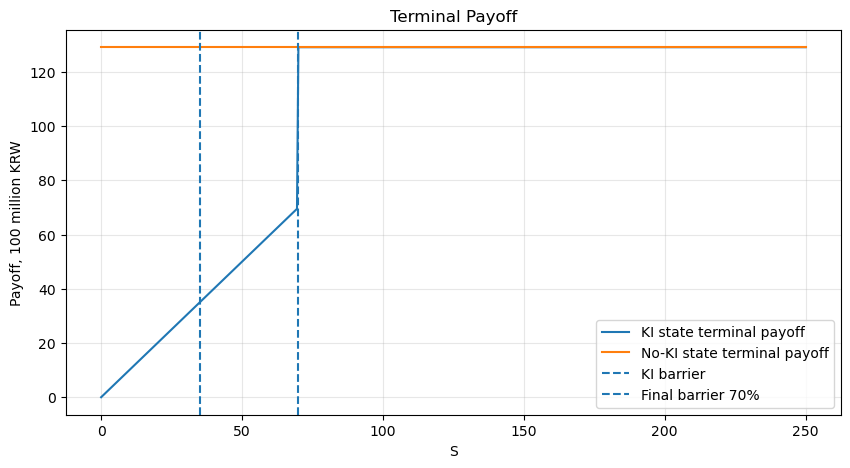

In [10]:
# ============================================================
# 4-9. Terminal Payoff
# ============================================================

def terminal_payoff_ki(S_GRID, els, S0):
    """
    KI가 이미 발생한 상태의 만기 payoff.
    """
    final_barrier = els.autocall_barriers[-1] * S0  # 70
    
    full_redemption = els.notional * (1 + els.annual_coupon * els.maturity_years)
    loss_redemption = els.notional * (S_GRID / S0)
    
    payoff = np.where(
        S_GRID >= final_barrier,
        full_redemption,
        loss_redemption
    )
    
    return payoff


def terminal_payoff_noki(S_GRID, els):
    """
    KI가 발생하지 않은 상태의 만기 payoff.
    """
    full_redemption = els.notional * (1 + els.annual_coupon * els.maturity_years)
    payoff = np.full_like(S_GRID, full_redemption, dtype=float)
    return payoff


V_ki_T = terminal_payoff_ki(S_GRID, els, S0)
V_noki_T = terminal_payoff_noki(S_GRID, els)

plt.figure(figsize=(10, 5))
plt.plot(S_GRID, V_ki_T / 1e8, label="KI state terminal payoff")
plt.plot(S_GRID, V_noki_T / 1e8, label="No-KI state terminal payoff")
plt.axvline(els.knock_in_barrier * S0, linestyle="--", label="KI barrier")
plt.axvline(els.autocall_barriers[-1] * S0, linestyle="--", label="Final barrier 70%")
plt.title("Terminal Payoff")
plt.xlabel("S")
plt.ylabel("Payoff, 100 million KRW")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

# x축은 만기 지수임

1. 조기상환이 되면
   → 낙인 여부와 상관없이 조기상환 payoff 지급 후 종료

2. 조기상환이 안 되고 만기까지 감

   2-1. 낙인이 한 번도 발생하지 않음
        → 만기 지수가 낮아도 원금 + 쿠폰 지급

   2-2. 낙인이 한 번이라도 발생함
        → 만기 지수를 봄

        a. 만기 지수 >= 70%
           → 원금 + 쿠폰 지급

        b. 만기 지수 < 70%
           → 원금 × (만기 지수 / 최초 기준 지수)


그래프에서 파란색 KI state terminal payoff가 의미하는 건:

낙인 발생 상태에서 만기까지 갔을 때,
만기 지수가 70% 아래면 KOSPI200 성과를 따라가고,
만기 지수가 70% 이상이면 다시 원금 + 쿠폰으로 회복된다.

In [11]:
# ============================================================
# 4-10. Run FDM Backward Induction
# ============================================================

def run_fdm_els(
    S_GRID,
    N_STEPS,
    dt,
    els,
    S0,
    r,
    sigma,
    autocall_event_dict
):
    """
    Step-down KI ELS value grid 계산.
    
    Returns
    -------
    V_ki_grid : np.ndarray
        shape = (N_STEPS + 1, len(S_GRID))
    V_noki_grid : np.ndarray
        shape = (N_STEPS + 1, len(S_GRID))
    """
    
    n_s = len(S_GRID)
    
    V_ki_grid = np.zeros((N_STEPS + 1, n_s))
    V_noki_grid = np.zeros((N_STEPS + 1, n_s))
    
    # terminal condition
    V_ki_grid[-1, :] = terminal_payoff_ki(S_GRID, els, S0)
    V_noki_grid[-1, :] = terminal_payoff_noki(S_GRID, els)
    
    # 만기 시점에서 S <= KI barrier이면 No-KI 상태 불가능
    ki_level = els.knock_in_barrier * S0
    V_noki_grid[-1, S_GRID <= ki_level] = V_ki_grid[-1, S_GRID <= ki_level]
    
    # backward induction
    for t in range(N_STEPS - 1, -1, -1):
        
        # boundary at current t
        V_ki_boundary = V_ki_grid[t + 1, :].copy()
        V_noki_boundary = V_noki_grid[t + 1, :].copy()
        
        V_ki_boundary, V_noki_boundary = apply_boundary_conditions(
            V_ki_boundary,
            V_noki_boundary,
            time_index=t,
            S_GRID=S_GRID,
            els=els,
            r=r,
            dt=dt
        )
        
        # implicit step
        V_ki_t = implicit_step(
            V_next=V_ki_grid[t + 1, :],
            S_GRID=S_GRID,
            r=r,
            sigma=sigma,
            dt=dt,
            boundary_low=V_ki_boundary[0],
            boundary_high=V_ki_boundary[-1]
        )
        
        V_noki_t = implicit_step(
            V_next=V_noki_grid[t + 1, :],
            S_GRID=S_GRID,
            r=r,
            sigma=sigma,
            dt=dt,
            boundary_low=V_noki_boundary[0],
            boundary_high=V_noki_boundary[-1]
        )
        
        # No-KI 상태에서 KI barrier 이하로 내려가면 KI state로 전환
        V_noki_t[S_GRID <= ki_level] = V_ki_t[S_GRID <= ki_level]
        
        # autocall date 처리
        # t 시점이 조기상환 평가일이면 barrier 이상에서 payoff로 고정
        if t in autocall_event_dict:
            event = autocall_event_dict[t]
            barrier_level = event["barrier"]
            year_frac = event["year_fraction"]
            
            redemption_payoff = els.notional * (1 + els.annual_coupon * year_frac)
            
            called_region = S_GRID >= barrier_level
            
            V_ki_t[called_region] = redemption_payoff
            V_noki_t[called_region] = redemption_payoff
        
        V_ki_grid[t, :] = V_ki_t
        V_noki_grid[t, :] = V_noki_t
    
    return V_ki_grid, V_noki_grid


V_ki_grid, V_noki_grid = run_fdm_els(
    S_GRID=S_GRID,
    N_STEPS=N_STEPS,
    dt=dt,
    els=els,
    S0=S0,
    r=RISK_FREE_RATE,
    sigma=SIGMA,
    autocall_event_dict=autocall_event_dict
)

print("V_ki_grid shape:", V_ki_grid.shape)
print("V_noki_grid shape:", V_noki_grid.shape)

V_ki_grid shape: (780, 501)
V_noki_grid shape: (780, 501)


# 4-11 최초시점 ELS value 확인
현재는 발행 직후이고 아직 knock-in이 발생하지 않았으므로, 초기 가치는 NO-KI state의 S = 100 이다.

In [12]:
# ============================================================
# 4-11. Initial ELS Value
# ============================================================

def linear_interpolate(x_grid, y_grid, x):
    """
    1차 선형보간 함수
    """
    return np.interp(x, x_grid, y_grid)


initial_els_value = linear_interpolate(
    S_GRID,
    V_noki_grid[0, :],
    S0
)

print("Initial ELS value:", initial_els_value)
print("Initial ELS value / notional:", initial_els_value / els.notional)

Initial ELS value: 10384641573.72093
Initial ELS value / notional: 1.038464157372093


# 4-12 FDM value surface 일부 확인

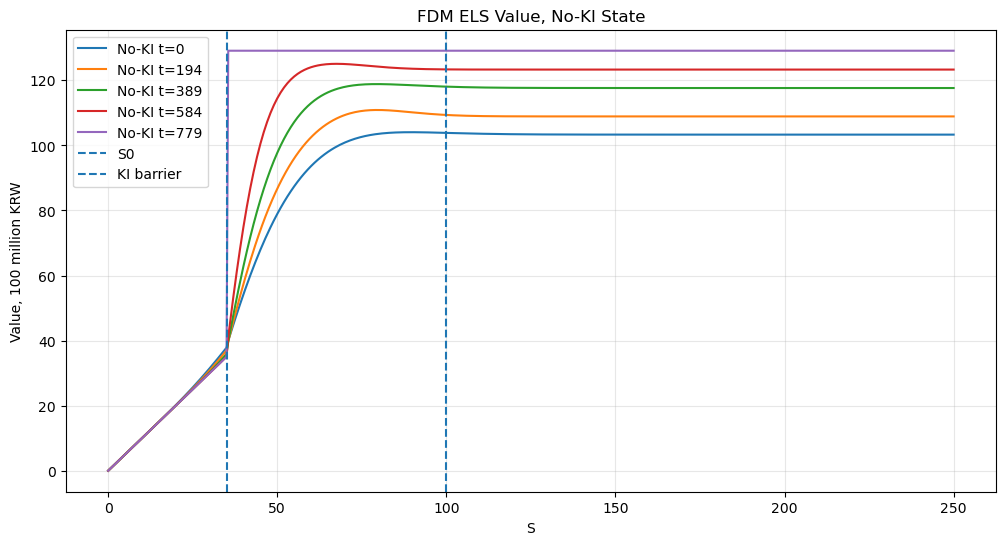

In [13]:
# ============================================================
# 4-12. Plot ELS Value by Time
# ============================================================

time_indices_to_plot = [
    0,
    int(N_STEPS * 0.25),
    int(N_STEPS * 0.50),
    int(N_STEPS * 0.75),
    N_STEPS
]

plt.figure(figsize=(12, 6))

for idx in time_indices_to_plot:
    plt.plot(
        S_GRID,
        V_noki_grid[idx, :] / 1e8,
        label=f"No-KI t={idx}"
    )

plt.axvline(S0, linestyle="--", label="S0")
plt.axvline(els.knock_in_barrier * S0, linestyle="--", label="KI barrier")
plt.title("FDM ELS Value, No-KI State")
plt.xlabel("S")
plt.ylabel("Value, 100 million KRW")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

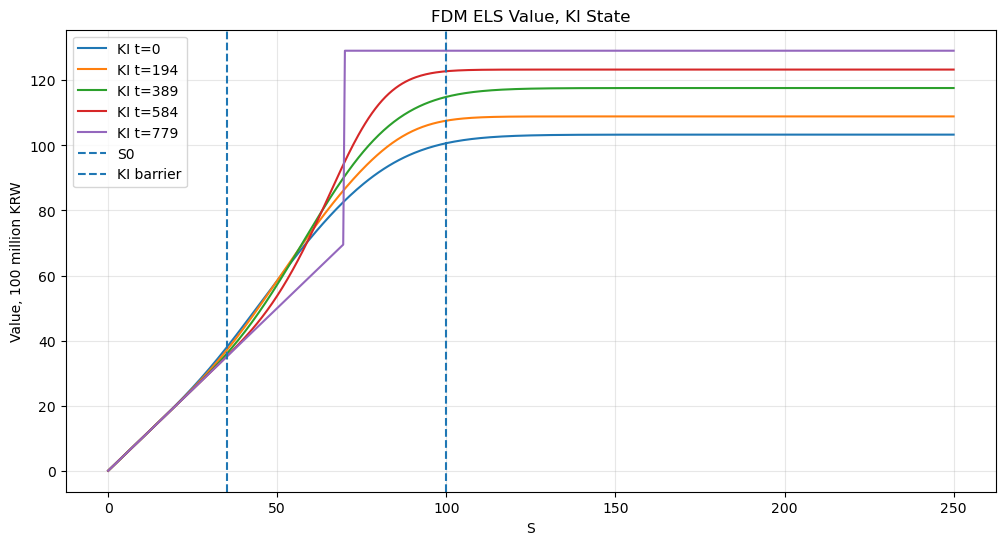

In [14]:
plt.figure(figsize=(12, 6))

for idx in time_indices_to_plot:
    plt.plot(
        S_GRID,
        V_ki_grid[idx, :] / 1e8,
        label=f"KI t={idx}"
    )

plt.axvline(S0, linestyle="--", label="S0")
plt.axvline(els.knock_in_barrier * S0, linestyle="--", label="KI barrier")
plt.title("FDM ELS Value, KI State")
plt.xlabel("S")
plt.ylabel("Value, 100 million KRW")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

# 4-13 Delta grid 계산
Delta는 가격 grid에 대해 중앙차분으로 계산한다.

In [15]:
# ============================================================
# 4-13. Calculate Delta Grid
# ============================================================

def calculate_delta_grid(V_grid, S_GRID):
    """
    value grid에서 delta grid 계산.
    delta = dV / dS
    """
    delta_grid = np.zeros_like(V_grid)
    
    # 중앙차분
    delta_grid[:, 1:-1] = (
        V_grid[:, 2:] - V_grid[:, :-2]
    ) / (
        S_GRID[2:] - S_GRID[:-2]
    )
    
    # 양 끝은 one-sided difference
    delta_grid[:, 0] = (
        V_grid[:, 1] - V_grid[:, 0]
    ) / (
        S_GRID[1] - S_GRID[0]
    )
    
    delta_grid[:, -1] = (
        V_grid[:, -1] - V_grid[:, -2]
    ) / (
        S_GRID[-1] - S_GRID[-2]
    )
    
    return delta_grid


delta_ki_grid = calculate_delta_grid(V_ki_grid, S_GRID)
delta_noki_grid = calculate_delta_grid(V_noki_grid, S_GRID)

print("delta_ki_grid shape:", delta_ki_grid.shape)
print("delta_noki_grid shape:", delta_noki_grid.shape)

delta_ki_grid shape: (780, 501)
delta_noki_grid shape: (780, 501)


In [16]:
# ============================================================
# 4-14. Initial Delta
# ============================================================

initial_delta = linear_interpolate(
    S_GRID,
    delta_noki_grid[0, :],
    S0
)

print("Initial delta at S0=100, No-KI state:", initial_delta)



Initial delta at S0=100, No-KI state: -2846917.0774707794


delta: 정규화된 KOSPI200 지수 1포인트 변화에 대한 ELS value 변화액
S = 100 기준으로 S가 1 움직일 때 발행자 liability가 얼마나 변하는지

# 4-15 Delta 그래프 확인

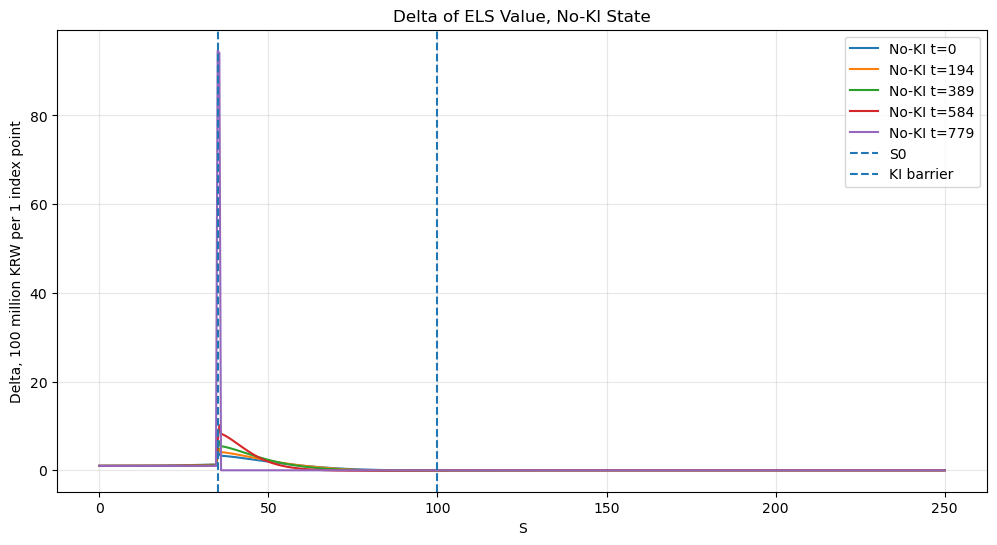

In [17]:
# ============================================================
# 4-15. Plot Delta by Time
# ============================================================

plt.figure(figsize=(12, 6))

for idx in time_indices_to_plot:
    plt.plot(
        S_GRID,
        delta_noki_grid[idx, :] / 1e8,
        label=f"No-KI t={idx}"
    )

plt.axvline(S0, linestyle="--", label="S0")
plt.axvline(els.knock_in_barrier * S0, linestyle="--", label="KI barrier")
plt.title("Delta of ELS Value, No-KI State")
plt.xlabel("S")
plt.ylabel("Delta, 100 million KRW per 1 index point")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

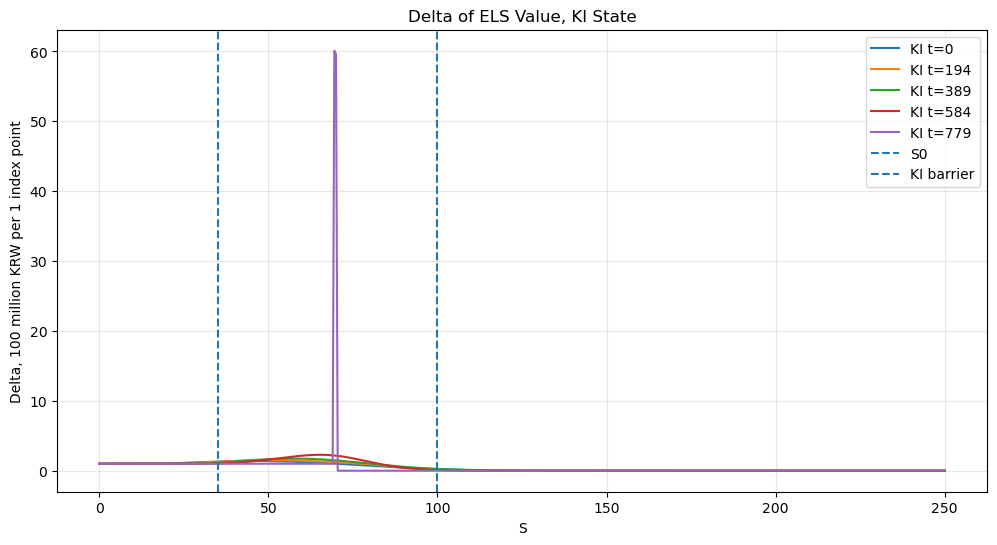

In [18]:
plt.figure(figsize=(12, 6))

for idx in time_indices_to_plot:
    plt.plot(
        S_GRID,
        delta_ki_grid[idx, :] / 1e8,
        label=f"KI t={idx}"
    )

plt.axvline(S0, linestyle="--", label="S0")
plt.axvline(els.knock_in_barrier * S0, linestyle="--", label="KI barrier")
plt.title("Delta of ELS Value, KI State")
plt.xlabel("S")
plt.ylabel("Delta, 100 million KRW per 1 index point")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

# 4-16 path별 FDM value / delta lookup 함수

나중에 dynamic hedge에서 path별로 현재 St에 해당하는 delta를 가져와야 한다.

In [19]:
# ============================================================
# 4-16. Lookup Functions
# dynamic hedge에서 path별로 현제 St에 해당하는 delta를 가져와야 함
# ============================================================

def lookup_value_delta(
    S,
    time_index,
    knock_in_state,
    S_GRID,
    V_ki_grid,
    V_noki_grid,
    delta_ki_grid,
    delta_noki_grid
):
    """
    특정 시점, 특정 가격, KI 상태에서 value와 delta를 보간해 가져온다.
    
    knock_in_state:
    - True  : KI already occurred
    - False : No-KI state
    """
    
    time_index = int(np.clip(time_index, 0, V_ki_grid.shape[0] - 1))
    S = float(np.clip(S, S_GRID[0], S_GRID[-1]))
    
    if knock_in_state:
        value = np.interp(S, S_GRID, V_ki_grid[time_index, :])
        delta = np.interp(S, S_GRID, delta_ki_grid[time_index, :])
    else:
        value = np.interp(S, S_GRID, V_noki_grid[time_index, :])
        delta = np.interp(S, S_GRID, delta_noki_grid[time_index, :])
    
    return value, delta


# 테스트
test_value, test_delta = lookup_value_delta(
    S=100,
    time_index=0,
    knock_in_state=False,
    S_GRID=S_GRID,
    V_ki_grid=V_ki_grid,
    V_noki_grid=V_noki_grid,
    delta_ki_grid=delta_ki_grid,
    delta_noki_grid=delta_noki_grid
)

print("Test value:", test_value)
print("Test delta:", test_delta)

Test value: 10384641573.72093
Test delta: -2846917.0774707794


In [20]:
# ============================================================
# 4-17. Save Section 4 Outputs
# ============================================================

np.save(OUTPUT_DIR / "fdm_S_GRID.npy", S_GRID)
np.save(OUTPUT_DIR / "fdm_V_ki_grid.npy", V_ki_grid)
np.save(OUTPUT_DIR / "fdm_V_noki_grid.npy", V_noki_grid)
np.save(OUTPUT_DIR / "fdm_delta_ki_grid.npy", delta_ki_grid)
np.save(OUTPUT_DIR / "fdm_delta_noki_grid.npy", delta_noki_grid)

fdm_summary = pd.DataFrame([{
    "S0": S0,
    "S_MAX": S_MAX,
    "N_S": N_S,
    "N_STEPS": N_STEPS,
    "dt": dt,
    "dS": dS,
    "sigma": SIGMA,
    "risk_free_rate": RISK_FREE_RATE,
    "initial_els_value": initial_els_value,
    "initial_els_value_over_notional": initial_els_value / els.notional,
    "initial_delta": initial_delta,
}])

fdm_summary_path = OUTPUT_DIR / "fdm_summary.csv"
fdm_summary.to_csv(fdm_summary_path, index=False, encoding="utf-8-sig")

print("Saved FDM grids to:", OUTPUT_DIR)
print("Saved FDM summary to:", fdm_summary_path)

fdm_summary

Saved FDM grids to: C:\Users\Yeonsoo\Desktop\project\ELS hege 5.19\output
Saved FDM summary to: C:\Users\Yeonsoo\Desktop\project\ELS hege 5.19\output\fdm_summary.csv


,S0,S_MAX,N_S,N_STEPS,dt,dS,sigma,risk_free_rate,initial_els_value,initial_els_value_over_notional,initial_delta
0,100,250,500,779,0.003851,0.500000,0.272042,0.030000,"10,384,641,573.720930",1.038464,"-2,846,917.077471"
